# How well do jobs and skills pay for Data Analysts?

### Methodology

1. Evaluate median salary for top 6 data jobs.
2. Find median salary per skill for Data Analysts.
3. Visualize for highest paying skills and most demanded skills.

In [5]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

/opt/anaconda3/envs/python_course/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
df_India  =df[(df['job_country']== 'India')].dropna(subset=['salary_year_avg'])

In [7]:
job_titles = df_India ['job_title_short'].value_counts().index[:6].tolist()
job_titles

['Data Engineer',
 'Data Analyst',
 'Data Scientist',
 'Machine Learning Engineer',
 'Senior Data Engineer',
 'Software Engineer']

In [ ]:
df_India_top6 = df_India[df_India['job_title_short'].isin(job_titles)]

In [ ]:
job_order = df_India_top6.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending = False).index

/opt/anaconda3/envs/python_course/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


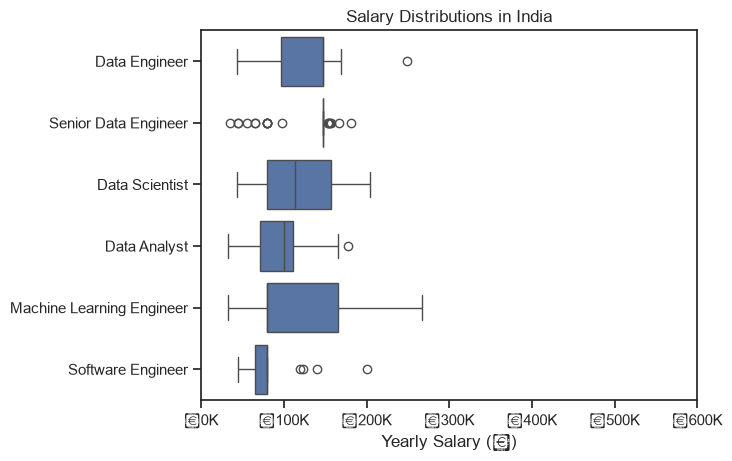

In [ ]:
sns.boxplot(data=df_India_top6, x='salary_year_avg', y='job_title_short',order =job_order)
sns.set_theme(style='ticks')

# this is all the same
plt.title('Salary Distributions in India')
plt.xlabel('Yearly Salary (₹)')
plt.ylabel('')
plt.xlim(0, 600000)
ticks_x = plt.FuncFormatter(lambda y, pos: f'₹{int(y/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)
plt.show()

# Investigate Median Salary Vs Skill For Data Analysts 

In [8]:
df_DA_India = df[
    (df['job_title_short'] == 'Data Analyst') &
    (df['job_country'] == 'India')
].copy()

df_DA_India = df_DA_India.dropna(subset=['salary_year_avg'])

In [10]:
df_DA_India = df_DA_India.explode('job_skills')
df_DA_India[['salary_year_avg','job_skills']].head(5)

,salary_year_avg,job_skills
11412,50400.0,python
11412,50400.0,sql
11412,50400.0,aws
11412,50400.0,azure
11412,50400.0,excel


In [18]:
df_DA_top_pay =df_DA_India.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='median')
df_DA_top_pay = df_DA_top_pay.head(10)

In [17]:
df_DA_skills = df_DA_India.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='count',ascending=False)
df_DA_skills = df_DA_skills.head(10).sort_values(by='median',ascending=False)
df_DA_skills

,count,median
job_skills,,
power bi,17,111175.0
spark,11,111175.0
tableau,20,108087.5
excel,39,98500.0
sql,46,96050.0
python,36,96050.0
azure,15,93600.0
r,18,79200.0
aws,12,79200.0


/var/folders/61/862l0v2938d4j8y5490vhyz40000gn/T/ipykernel_63777/4161832118.py:52: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/envs/python_course/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


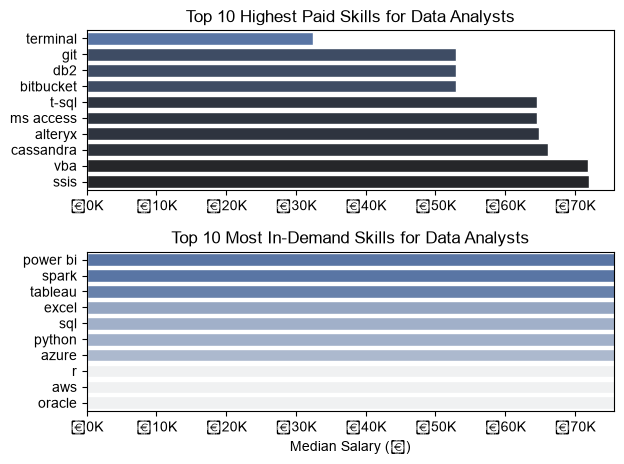

In [19]:
fig, ax = plt.subplots(2, 1)

sns.set_theme(style='ticks')

# Top 10 Highest Paid Skills for Data Analysts
sns.barplot(
    data=df_DA_top_pay,
    x='median',
    y=df_DA_top_pay.index,
    hue='median',
    ax=ax[0],
    palette='dark:b_r'
)
ax[0].legend().remove()

# original code:
# df_DA_top_pay[::-1].plot(kind='barh', y='median', ax=ax[0], legend=False)

ax[0].set_title('Top 10 Highest Paid Skills for Data Analysts')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'₹{int(x/1000)}K')
)

# Top 10 Most In-Demand Skills for Data Analysts
sns.barplot(
    data=df_DA_skills,
    x='median',
    y=df_DA_skills.index,
    hue='median',
    ax=ax[1],
    palette='light:b'
)
ax[1].legend().remove()

# original code:
# df_DA_skills[::-1].plot(kind='barh', y='median', ax=ax[1], legend=False)

ax[1].set_title('Top 10 Most In-Demand Skills for Data Analysts')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (₹)')
ax[1].set_xlabel('Median Salary (₹)')

# Set the same x-axis limits as the first plot
ax[1].set_xlim(ax[0].get_xlim())

ax[1].xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'₹{int(x/1000)}K')
)

plt.tight_layout()
plt.show()